# Audit a human–mouse mixture with GAUGE

**Your task.** Decide which cell groups to investigate for quality-control (QC) effects and what to check next. You will compare expression-based and QC-based support for the same Leiden groups, choose two groups to follow up, then reveal species labels as a separate check.

This example uses the complete Mixture 1 10x Chromium v2 sample from Ding et al. (GEO GSE132044). The dataset has 3,159 cells and 15,796 matched human/mouse gene features. The recorded species labels give us a way to check some multiplets, which are captures that contain more than one cell.

## 0. Install GAUGE and place the data beside this notebook

Use Python 3.10 or newer. In a terminal on macOS or Linux, create an environment and activate it.

```bash
python -m venv .venv
source .venv/bin/activate
```

In Windows PowerShell, activate the environment with `.venv\Scripts\Activate.ps1`.

Install the software and tutorial dependencies from the public GAUGE repository. If you already have a checkout, run the install command from its root.

```bash
git clone https://github.com/zhanglabtools/gauge-sc.git
cd gauge-sc
python -m pip install ".[tutorial]" jupyterlab
```

To install from a downloaded wheel, pass its local path with the tutorial extra. This example uses version `0.1.0a2`.

```bash
python -m pip install "./gauge_sc-0.1.0a2-py3-none-any.whl[tutorial]" jupyterlab
```

Download **`ding_mixture.h5ad`** (about 28 MB) from [tutorial-data-v1](https://github.com/zhanglabtools/gauge-sc/releases/tag/tutorial-data-v1) and put it beside this notebook. You can also run this command from the notebook folder.

```bash
curl -fLO https://github.com/zhanglabtools/gauge-sc/releases/download/tutorial-data-v1/ding_mixture.h5ad
```

From that folder, run `jupyter lab`, open this notebook and select the environment you just installed. If you store the data elsewhere, set `data_dir` below to the folder containing the file. This notebook verifies the version-pinned file and runs with local data. The first cell should show **3,159 cells × 15,796 features**.

In [1]:
import os
from pathlib import Path

from IPython.display import display

import gauge_sc as gauge

data_dir = Path(os.environ.get("GAUGE_TUTORIAL_DATA") or ".")
source = gauge.datasets.load_example("ding_mixture", data_dir=data_dir, download=False)
qc_columns = ["nUMI", "nGene", "percent.mito"]
print(f"GAUGE {gauge.__version__} · {source.n_obs:,} cells × {source.n_vars:,} features")
display(source.obs[qc_columns].head(3))

GAUGE 0.1.0a2 · 3,159 cells × 15,796 features


,nUMI,nGene,percent.mito
cell_id,,,
Mixture1.10x-Chromium-v2.AAACCTGAGAGCAATT,26211,7833,5.436649
Mixture1.10x-Chromium-v2.AAACCTGAGTGAAGAG,36114,6559,8.276569
Mixture1.10x-Chromium-v2.AAACCTGCACAGGAGT,10899,3297,5.596844


`nUMI` is the captured molecule count, `nGene` is the number of detected genes, and `percent.mito` is the percentage of counts assigned to mitochondrial genes. These QC measurements were computed on the original gene set. The expression matrix combines counts for matched human and mouse genes so that the assay's species calls can be held aside until the group audit is complete.

## 1. Build the grouping and the two data views

Normalize and log-transform the combined expression counts, choose 2,000 highly variable genes and compute 30 principal components. Use those components to make one Leiden grouping at resolution 1.0. The **molecular view** answers how predictable those group labels are from expression. The **QC view** asks the same question using the three QC measurements. Both views use the same cells and labels. Keep the species flag in a separate variable while doing this.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np
import scanpy as sc
import seaborn as sns

sc.set_figure_params(dpi=110, frameon=False)

withheld = source.obs["mixed_species_multiplet_withheld"].copy()
adata = source.copy()
adata.obs = source.obs[qc_columns].copy()

sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2_000, flavor="seurat")
sc.pp.pca(adata, n_comps=30, mask_var="highly_variable", random_state=0)
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca", random_state=0)
sc.tl.leiden(
    adata, resolution=1.0, key_added="group", random_state=0,
    flavor="igraph", directed=False, n_iterations=2,
)
print(f"{adata.n_obs:,} cells · {adata.obs['group'].nunique()} Leiden groups")

3,159 cells · 16 Leiden groups


## 2. Compare group support and decide what to inspect

GAUGE evaluates how well each view predicts the fixed groups in five paired cross-validation folds. Each group's contribution combines its held-out recall with a weight based on the group's frequency. `audit()` subtracts the molecular contribution from the QC contribution, then subtracts the median of that difference across eligible groups. Eligibility here requires at least five cells from the group in every test fold.

Before reading any species labels, take the two eligible groups with the highest positive centered contrasts. This is the follow-up rule for this exercise. The optional mirror screen makes its own candidate calls. Read its status separately from the follow-up table.

In [3]:
result = gauge.evaluate(
    adata, groupby="group", n_splits=5, random_state=0, aggregation="pooled",
    views={
        "molecular": {"obsm": "X_pca"},
        "qc": {"obs": qc_columns, "log1p": ["nUMI", "nGene"]},
    },
)
audit = gauge.audit(
    result, reference="molecular", contrast="qc", min_test_cells=5,
    maximum_mirror_ratio=1 / 3,
)
ranked = audit.table.sort_values("contrast", ascending=False, kind="stable")
follow_up = ranked.loc[ranked["eligible"] & ranked["contrast"].gt(0)].head(2).copy()
display(follow_up[[
    "group", "n_cells", "reference_contribution", "contrast_contribution",
    "difference", "contrast", "candidate",
]].rename(columns={
    "reference_contribution": "molecular contribution",
    "contrast_contribution": "QC contribution",
    "difference": "QC − molecular",
    "contrast": "centered contrast",
    "candidate": "mirror flag",
}).round(5))
if not follow_up.empty:
    first = follow_up.iloc[0]
    print(
        f"Group {first['group']}: {first['difference']:.4f} raw difference "
        f"− ({audit.metadata['center']:.4f} median) = {first['contrast']:+.4f} centered."
    )
print("Mirror screen:", audit.metadata["screening"]["message"])

,group,n_cells,molecular contribution,QC contribution,QC − molecular,centered contrast,mirror flag
6,14,77,0.08583,0.06702,-0.01881,0.07512,False
0,0,100,0.10056,0.07651,-0.02405,0.06989,False


Group 14: -0.0188 raw difference − (-0.0939 median) = +0.0751 centered.
Mirror screen: Enough positive groups are available, but no observed threshold meets the requested positive/negative tail ratio.


**Read the table.** A centered contrast can be positive even when the raw difference is negative. The subtraction puts each group in context relative to the other eligible groups. In the recorded run the mirror screen found no threshold. The two rows are still useful as a descriptive shortlist for this exercise.

**Read the map.** All cells in a group inherit the same group contrast. Orange marks groups above the median, blue marks groups below it, and grey marks groups without sufficient test-fold support. Use the UMAP to locate the groups. The colors summarize predictability from the measured views and do not label individual cells as multiplets.

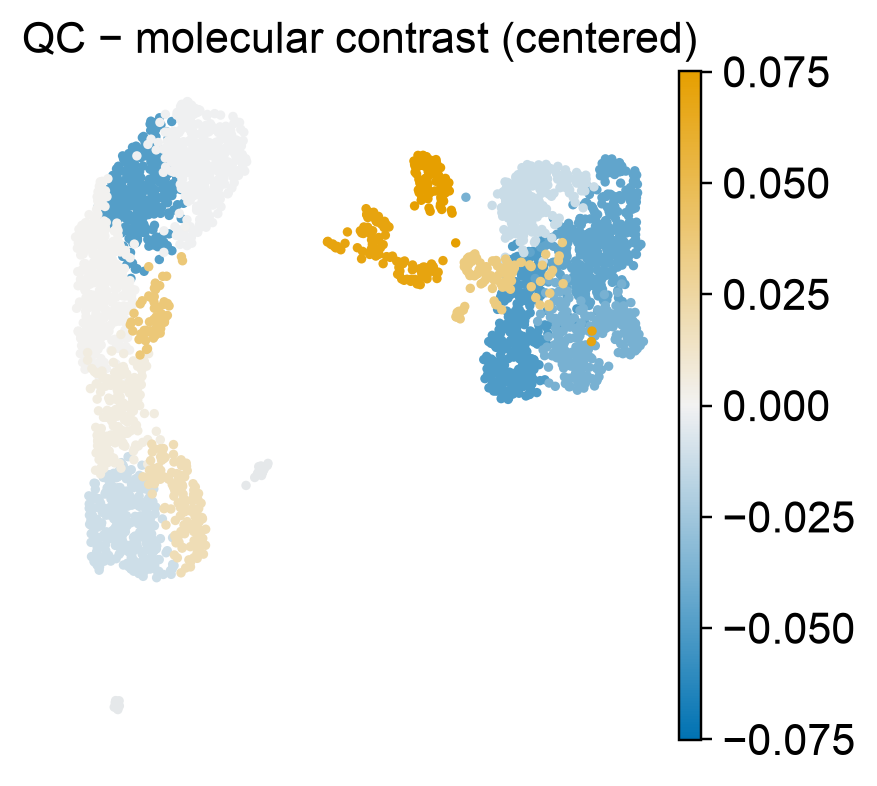

In [4]:
audit.write_to_adata(adata)
sc.tl.umap(adata, random_state=0)
cmap = LinearSegmentedColormap.from_list(
    "molecular_qc_contrast", ["#0072B2", "#F2F2F2", "#E69F00"]
)
scores = adata.obs["gauge_sc_audit_contrast"].dropna()
limit = float(np.quantile(np.abs(scores), 0.99)) or 1.0
sc.pl.umap(
    adata, color="gauge_sc_audit_contrast", cmap=cmap,
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    na_color="#E5E8EA", title="QC − molecular contrast (centered)",
)

## 3. Reveal species labels and choose the next check

Join the withheld flag by cell ID after the shortlist is fixed. The assay marks a cell as mixed-species when human and mouse counts each exceed 15% of the species-resolved total. Compare the mixed-species fractions and measured QC distributions in the shortlisted groups and in the remaining cells.

In [5]:
readout = adata.obs[["group", *qc_columns]].copy()
readout["mixed_species"] = withheld.reindex(adata.obs_names)
assert readout["mixed_species"].notna().all()

summary = readout.groupby("group", observed=True).agg(
    cells=("mixed_species", "size"),
    mixed_species_fraction=("mixed_species", "mean"),
    median_UMI=("nUMI", "median"),
    median_genes=("nGene", "median"),
    median_mito_percent=("percent.mito", "median"),
)
follow_up_summary = follow_up.set_index("group")[["contrast", "candidate"]].join(summary)
display(follow_up_summary.round(5))
for group, row in follow_up_summary.iterrows():
    print(
        f"Group {group}: {row.mixed_species_fraction:.1%} mixed-species; "
        f"median mitochondrial counts {row.median_mito_percent:.1f}%."
    )

,contrast,candidate,cells,mixed_species_fraction,median_UMI,median_genes,median_mito_percent
group,,,,,,,
14,0.07512,False,77,0.03896,6468.0,2363.0,30.64559
0,0.06989,False,100,0.95000,19034.5,6063.0,6.51973


Group 14: 3.9% mixed-species; median mitochondrial counts 30.6%.
Group 0: 95.0% mixed-species; median mitochondrial counts 6.5%.


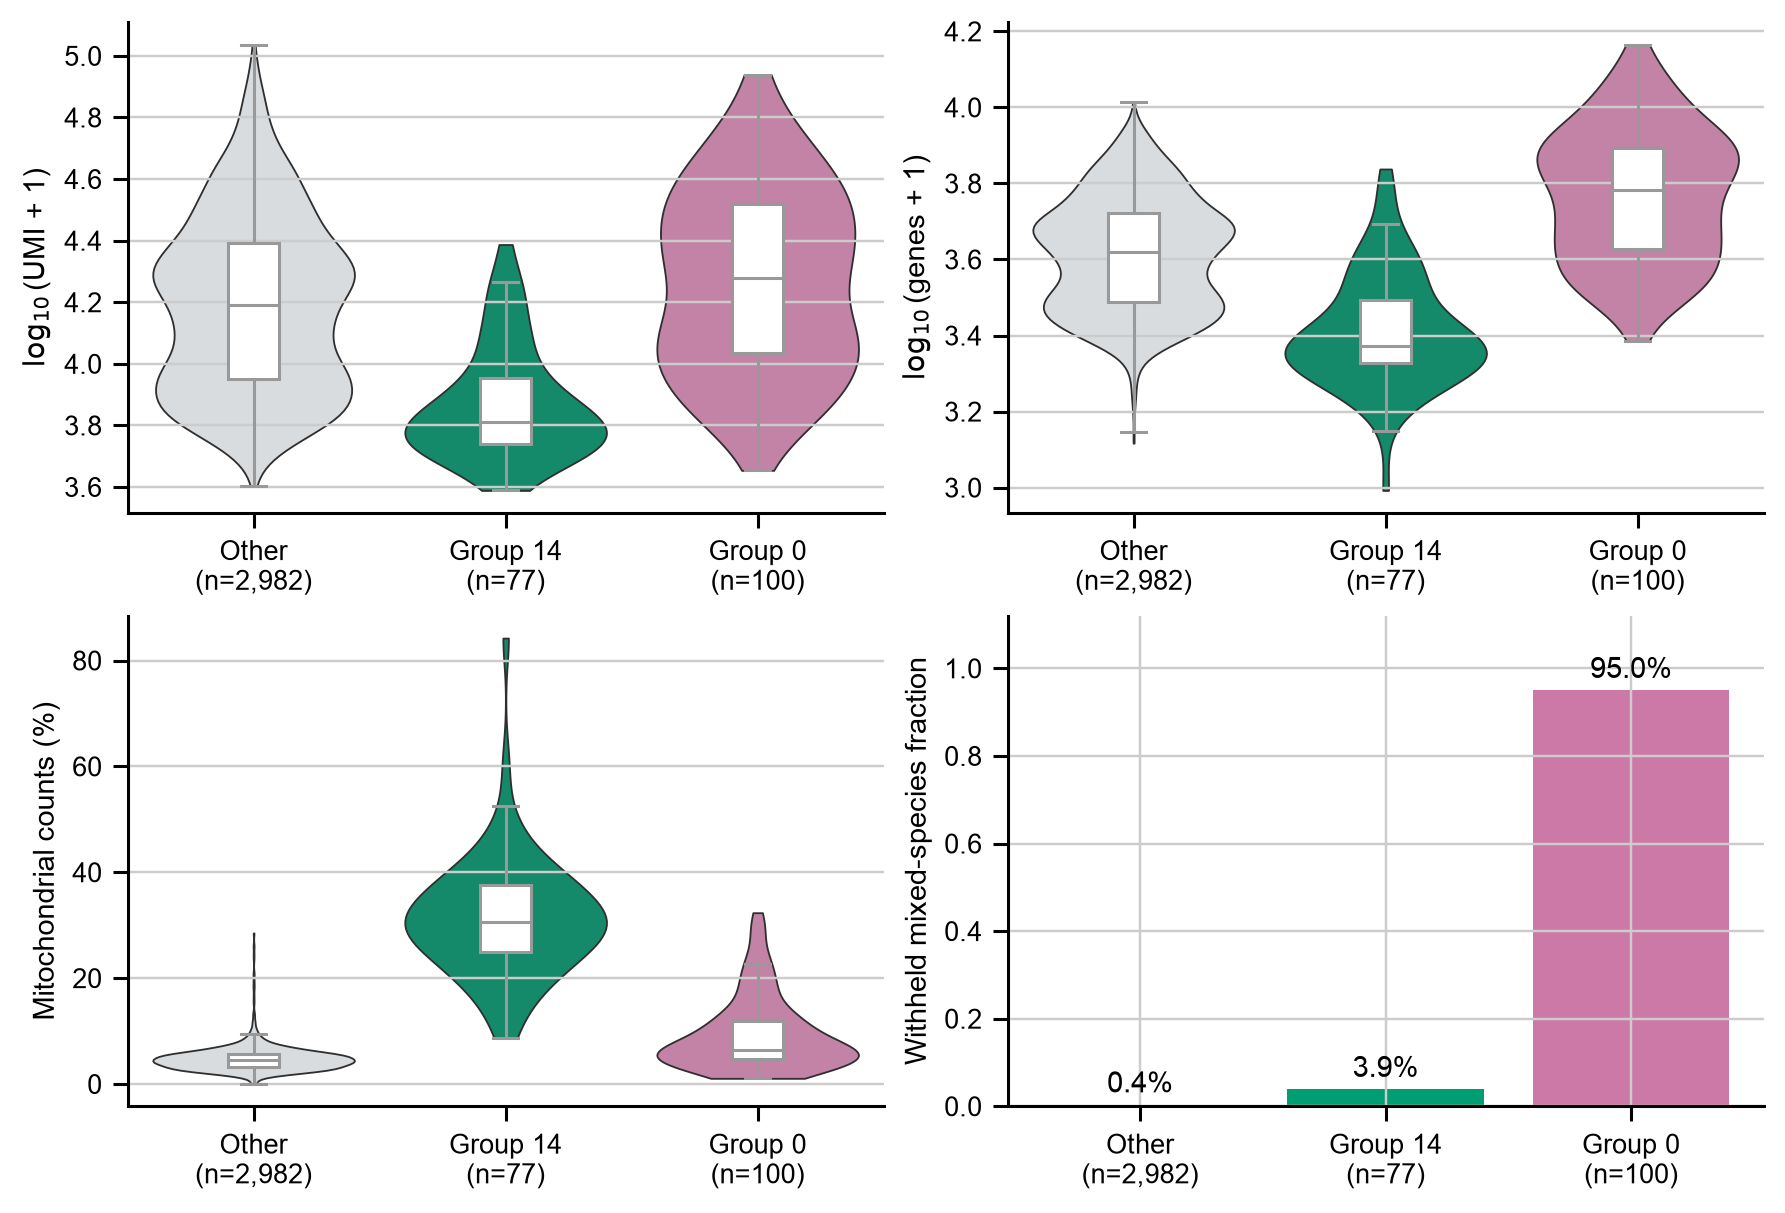

In [6]:
group_labels = {group: f"Group {group}" for group in follow_up["group"]}
readout["follow_up"] = readout["group"].astype(str).map(group_labels).fillna("Other")
readout["log10_counts"] = np.log10(readout["nUMI"] + 1)
readout["log10_genes"] = np.log10(readout["nGene"] + 1)
order = ["Other", *group_labels.values()]
palette = dict(zip(order, ["#D7DCE0", "#009E73", "#CC79A7"]))
counts = readout["follow_up"].value_counts()
metrics = [
    ("log10_counts", r"$\log_{10}$(UMI + 1)"), ("log10_genes", r"$\log_{10}$(genes + 1)"),
    ("percent.mito", "Mitochondrial counts (%)"),
]
with sns.plotting_context("paper"):
    fig, axes = plt.subplots(2, 2, figsize=(8, 5.4), layout="constrained")
    for ax, (metric, ylabel) in zip(axes.flat, metrics):
        sns.violinplot(
            data=readout, x="follow_up", y=metric, hue="follow_up", order=order,
            hue_order=order, palette=palette, legend=False, inner=None, cut=0,
            density_norm="width", linewidth=0.6, ax=ax,
        )
        sns.boxplot(
            data=readout, x="follow_up", y=metric, order=order, width=0.20,
            showfliers=False, color="white", ax=ax,
        )
        ax.set(xlabel="", ylabel=ylabel)
    fractions = readout.groupby("follow_up")["mixed_species"].mean().reindex(order)
    ax = axes[1, 1]
    bars = ax.bar(order, fractions, color=[palette[group] for group in order])
    ax.bar_label(bars, labels=[f"{fraction:.1%}" for fraction in fractions], padding=2)
    ax.set(ylabel="Withheld mixed-species fraction", ylim=(0, 1.12))
    for ax in axes.flat:
        ax.set_xticks(range(len(order)), [f"{group}\n(n={counts[group]:,})" for group in order])
    sns.despine(fig=fig)
    plt.show()

**Read the four panels together.** The first three panels show the distributions of UMI counts, detected genes and mitochondrial percentage. The fourth shows the withheld mixed-species fraction. `Other` combines all groups outside the shortlist for context.

- **Group 0 in the recorded run:** 95.0% of cells have a mixed-species flag. Follow up by inspecting independent doublet annotations or the species-resolved counts.
- **Group 14 in the recorded run:** 3.9% have a mixed-species flag and the median mitochondrial proportion is 30.6%. Inspect the mitochondrial and library-quality distributions before deciding how to handle this group.

Species labels detect mixed-species captures and can miss same-species multiplets. A high mitochondrial fraction warrants investigation in its sample context. The audit ranks groups for exploratory follow-up and the mirror screen does not control FDR. On another numerical backend, group IDs and borderline scores can vary. Compare the patterns in the plots and table rather than matching the Leiden IDs. [Numerical reproducibility](../../docs/numerical-reproducibility.md).

## Apply the audit to your own AnnData

Start with one AnnData object. It should have one row per cell, a precomputed grouping and measured numeric QC columns in `obs`, and a molecular embedding in `obsm`. Use the same filtered cells in both views. The example below runs on the tutorial data and has four lines to change for your sample. The count columns listed in `log1p` should be nonnegative and on their original count scale. Leave percentages untransformed for this example.

In [7]:
user_adata = adata  # Replace with sc.read_h5ad("my_sample.h5ad").
grouping = "group"  # Your categorical grouping column in .obs.
embedding = "X_pca"  # Your molecular representation in .obsm.
umi, genes, mito = "nUMI", "nGene", "percent.mito"  # Your QC columns in .obs.

user_result = gauge.evaluate(
    user_adata, groupby=grouping, n_splits=5, random_state=0,
    views={
        "molecular": {"obsm": embedding},
        "qc": {"obs": [umi, genes, mito], "log1p": [umi, genes]},
    },
)
user_audit = gauge.audit(user_result, reference="molecular", contrast="qc")
eligible = user_audit.table.query("eligible").sort_values("contrast", ascending=False)
display(eligible[["group", "n_cells", "contrast"]].head(5).round(5))

,group,n_cells,contrast
6,14,77,0.07512
0,0,100,0.06989
5,13,57,0.03801
3,11,97,0.03550
15,9,133,0.01873


Review finite contrasts alongside cell counts and the measured QC values. If a group is ineligible, inspect `user_audit.table["reason"]` and the per-fold support before drawing a conclusion. When an independent validation label is available, keep it out of preprocessing and shortlist selection, then join it by cell ID for follow-up. The minimal example returns the continuous ranking without enabling the optional mirror screen.

## Go further

[Reproduce Figure 4a–f](../../docs/reproduce-figure4.md) for the paper's two mixtures, across-method ROC and matched randomization. This tutorial uses a single dataset and one grouping.

[Use GAUGE with your agent](../../docs/agents.md) to request the same audit. Specify the grouping, the molecular embedding and the QC columns. Ask the agent to record the groups it would investigate before reading any validation labels.